In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
import xgboost as xgb

%matplotlib inline

PROJECT_ROOT = Path("/mnt/d/IDC409_Project15")
FIGURES_DIR  = PROJECT_ROOT / "reports" / "figures"
MODELS_DIR   = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Reload and re-prepare Ames data (same pipeline as Phase 5 and 6)
df = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "ames_housing" / "train.csv")

TARGET = 'SalePrice'
y = df[TARGET].copy()
X = df.drop(columns=[TARGET]).copy()

# Drop high-missing columns and Id
missing_pct   = X.isnull().mean() * 100
high_missing  = missing_pct[missing_pct > 40].index.tolist()
X = X.drop(columns=['Id'] + high_missing)

num_cols = X.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

# Fit imputers on the FULL dataset — we'll need them to process new inputs
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='constant', fill_value='Unknown')

X[num_cols] = num_imputer.fit_transform(X[num_cols])
X[cat_cols] = cat_imputer.fit_transform(X[cat_cols])

# Encode
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)
bool_cols  = X_encoded.select_dtypes(include='bool').columns
X_encoded[bool_cols] = X_encoded[bool_cols].astype(int)

# Store the column list — critical for making new predictions later
MODEL_COLUMNS = X_encoded.columns.tolist()

# Split and train
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

# Train the best model (XGBoost with same settings as Phase 6)
best_model = xgb.XGBRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=4,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, verbosity=0
)
best_model.fit(X_train, y_train)

# Quick sanity check
y_pred = best_model.predict(X_test)
print(f"Model retrained successfully.")
print(f"R² = {r2_score(y_test, y_pred):.4f}  |  MAE = ${mean_absolute_error(y_test, y_pred):,.0f}")
print(f"\nFeature columns: {len(MODEL_COLUMNS)}")

/tmp/ipykernel_6760/3439055401.py:31: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include='object').columns.tolist()


Model retrained successfully.
R² = 0.9182  |  MAE = $15,331

Feature columns: 239


In [2]:
# Save the trained model so it can be loaded without retraining
# joblib is the standard way to save sklearn-compatible models

joblib.dump(best_model,   MODELS_DIR / "xgboost_house_price.pkl")
joblib.dump(MODEL_COLUMNS, MODELS_DIR / "model_columns.pkl")

# Save median values for numeric features — used as defaults for missing inputs
num_medians = {col: float(X[col].median()) for col in num_cols}
pd.Series(num_medians).to_json(MODELS_DIR / "numeric_medians.json")

print("Saved to models/ folder:")
print(f"  xgboost_house_price.pkl  — the trained model")
print(f"  model_columns.pkl        — list of expected feature columns")
print(f"  numeric_medians.json     — default values for missing numeric inputs")

Saved to models/ folder:
  xgboost_house_price.pkl  — the trained model
  model_columns.pkl        — list of expected feature columns
  numeric_medians.json     — default values for missing numeric inputs


In [3]:
def predict_house_price(input_features: dict) -> dict:
    """
    Predict the sale price of a house given its features.
    
    Only provide the features you know — everything else is filled in
    with the median value from the training data.
    
    Key features that matter most (from SHAP analysis):
        OverallQual   : Overall quality rating (1=Poor to 10=Excellent)
        GrLivArea     : Above-ground living area in square feet
        GarageCars    : Garage capacity (number of cars)
        TotalBsmtSF   : Total basement area in square feet
        1stFlrSF      : First floor area in square feet
        YearBuilt     : Year the house was originally built
        YearRemodAdd  : Year of last remodel (same as YearBuilt if no remodel)
        Neighborhood  : Neighborhood name (e.g. 'NAmes', 'NridgHt', 'Crawfor')
        KitchenQual   : Kitchen quality (Ex=Excellent, Gd=Good, TA=Typical, Fa=Fair)
        BsmtQual      : Basement quality (Ex, Gd, TA, Fa, NA)
    
    Returns dict with predicted price, confidence range, and input summary.
    """
    # Step 1: Start with a row of median values for all numeric features
    row = num_medians.copy()
    
    # Step 2: Override with whatever the user provided
    row.update(input_features)
    
    # Step 3: Convert to DataFrame with one row
    input_df = pd.DataFrame([row])
    
    # Step 4: Fill any remaining numeric columns not in input
    for col in num_cols:
        if col not in input_df.columns:
            input_df[col] = num_medians.get(col, 0)
    
    # Step 5: Fill categorical columns not provided with 'Unknown'
    for col in cat_cols:
        if col not in input_df.columns:
            input_df[col] = 'Unknown'
    
    # Step 6: One-hot encode (same as training)
    input_encoded = pd.get_dummies(input_df, columns=cat_cols, drop_first=True)
    bool_c = input_encoded.select_dtypes(include='bool').columns
    input_encoded[bool_c] = input_encoded[bool_c].astype(int)
    
    # Step 7: Align columns to match training — add missing cols as 0,
    #         drop any extra cols that weren't in training
    input_aligned = input_encoded.reindex(columns=MODEL_COLUMNS, fill_value=0)
    
    # Step 8: Predict
    predicted_price = float(best_model.predict(input_aligned)[0])
    
    # Step 9: Build a ±10% confidence range
    # (simplified — a proper interval would use quantile regression)
    lower = predicted_price * 0.90
    upper = predicted_price * 1.10
    
    return {
        'predicted_price':  round(predicted_price),
        'confidence_low':   round(lower),
        'confidence_high':  round(upper),
        'key_inputs_used':  {k: v for k, v in input_features.items()
                             if k in num_cols + cat_cols}
    }

print("predict_house_price() function defined.")
print("Ready to predict!")

predict_house_price() function defined.
Ready to predict!


In [4]:
def print_prediction(label, result):
    print(f"\n{'='*50}")
    print(f"  {label}")
    print(f"{'='*50}")
    print(f"  Predicted price : ${result['predicted_price']:>10,.0f}")
    print(f"  Confidence range: ${result['confidence_low']:>10,.0f}"
          f"  –  ${result['confidence_high']:,.0f}")
    print(f"\n  Key features used:")
    for k, v in result['key_inputs_used'].items():
        print(f"    {k:<20} : {v}")

# ── House 1: Small, older, basic quality ──────────────────────────
house1 = predict_house_price({
    'OverallQual'  : 4,
    'GrLivArea'    : 900,
    'GarageCars'   : 1,
    'TotalBsmtSF'  : 600,
    '1stFlrSF'     : 900,
    'YearBuilt'    : 1960,
    'YearRemodAdd' : 1960,
    'KitchenQual'  : 'TA',
    'BsmtQual'     : 'TA',
})
print_prediction("House 1 — Small & older (expect ~$80k–$130k)", house1)

# ── House 2: Medium size, decent quality ──────────────────────────
house2 = predict_house_price({
    'OverallQual'  : 6,
    'GrLivArea'    : 1500,
    'GarageCars'   : 2,
    'TotalBsmtSF'  : 1000,
    '1stFlrSF'     : 1000,
    'YearBuilt'    : 1995,
    'YearRemodAdd' : 2005,
    'KitchenQual'  : 'Gd',
    'BsmtQual'     : 'Gd',
})
print_prediction("House 2 — Medium & decent (expect ~$170k–$220k)", house2)

# ── House 3: Large, new, high quality ────────────────────────────
house3 = predict_house_price({
    'OverallQual'  : 9,
    'GrLivArea'    : 2800,
    'GarageCars'   : 3,
    'TotalBsmtSF'  : 2000,
    '1stFlrSF'     : 2000,
    'YearBuilt'    : 2008,
    'YearRemodAdd' : 2008,
    'KitchenQual'  : 'Ex',
    'BsmtQual'     : 'Ex',
})
print_prediction("House 3 — Large & high quality (expect ~$350k–$500k)", house3)


  House 1 — Small & older (expect ~$80k–$130k)
  Predicted price : $    89,141
  Confidence range: $    80,227  –  $98,055

  Key features used:
    OverallQual          : 4
    GrLivArea            : 900
    GarageCars           : 1
    TotalBsmtSF          : 600
    1stFlrSF             : 900
    YearBuilt            : 1960
    YearRemodAdd         : 1960
    KitchenQual          : TA
    BsmtQual             : TA

  House 2 — Medium & decent (expect ~$170k–$220k)
  Predicted price : $   158,823
  Confidence range: $   142,941  –  $174,705

  Key features used:
    OverallQual          : 6
    GrLivArea            : 1500
    GarageCars           : 2
    TotalBsmtSF          : 1000
    1stFlrSF             : 1000
    YearBuilt            : 1995
    YearRemodAdd         : 2005
    KitchenQual          : Gd
    BsmtQual             : Gd

  House 3 — Large & high quality (expect ~$350k–$500k)
  Predicted price : $   369,180
  Confidence range: $   332,262  –  $406,099

  Key features us

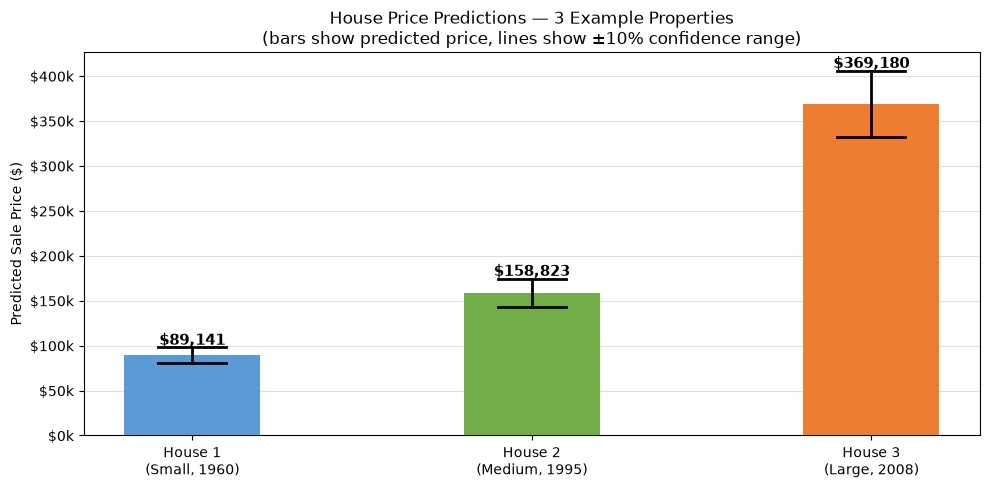

Saved: prediction_examples.png


In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

houses  = ['House 1\n(Small, 1960)', 'House 2\n(Medium, 1995)', 'House 3\n(Large, 2008)']
prices  = [house1['predicted_price'], house2['predicted_price'], house3['predicted_price']]
lows    = [house1['confidence_low'],  house2['confidence_low'],  house3['confidence_low']]
highs   = [house1['confidence_high'], house2['confidence_high'], house3['confidence_high']]
colors  = ['#5B9BD5', '#70AD47', '#ED7D31']

bars = ax.bar(houses, prices, color=colors, width=0.4, zorder=3)

# Add confidence interval lines
for i, (low, high, price) in enumerate(zip(lows, highs, prices)):
    ax.plot([i, i], [low, high], color='black', linewidth=2, zorder=4)
    ax.plot([i-0.1, i+0.1], [low, low],   color='black', linewidth=2, zorder=4)
    ax.plot([i-0.1, i+0.1], [high, high], color='black', linewidth=2, zorder=4)
    ax.text(i, high + 3000, f"${price:,.0f}",
            ha='center', fontsize=11, fontweight='bold')

ax.set_title("House Price Predictions — 3 Example Properties\n"
             "(bars show predicted price, lines show ±10% confidence range)",
             fontsize=12)
ax.set_ylabel("Predicted Sale Price ($)")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}k")
)
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "prediction_examples.png", bbox_inches='tight')
plt.show()
print("Saved: prediction_examples.png")

In [6]:
# Show how accurate the model is across different price ranges
# This is the "compare error in rupees and percentage" the rubric asks for

results_df = pd.DataFrame({
    'Actual':    y_test.values,
    'Predicted': y_pred,
})
results_df['Error']     = (results_df['Actual'] - results_df['Predicted']).abs()
results_df['Error_Pct'] = (results_df['Error'] / results_df['Actual'] * 100)

# Bin houses by price range
bins   = [0, 100000, 150000, 200000, 250000, 350000, 1000000]
labels = ['<$100k', '$100-150k', '$150-200k', '$200-250k', '$250-350k', '>$350k']
results_df['Price_Range'] = pd.cut(results_df['Actual'], bins=bins, labels=labels)

error_by_range = results_df.groupby('Price_Range', observed=True).agg(
    Count        = ('Actual', 'count'),
    Mean_Error   = ('Error', 'mean'),
    Mean_Pct_Err = ('Error_Pct', 'mean'),
    Within_10pct = ('Error_Pct', lambda x: (x < 10).sum())
).round(1)

error_by_range['Within_10pct_%'] = (
    error_by_range['Within_10pct'] / error_by_range['Count'] * 100
).round(1)

print("Model accuracy by price range:")
print("="*72)
print(f"{'Range':<14} {'Count':>6} {'Mean Error':>12} {'Mean % Err':>12} "
      f"{'Within 10%':>12}")
print("-"*72)
for idx, row in error_by_range.iterrows():
    print(f"{str(idx):<14} {int(row['Count']):>6} "
          f"${row['Mean_Error']:>10,.0f} {row['Mean_Pct_Err']:>11.1f}% "
          f"{row['Within_10pct_%']:>11.1f}%")
print("="*72)

overall_within_10 = (results_df['Error_Pct'] < 10).mean() * 100
print(f"\nOverall: {overall_within_10:.1f}% of houses predicted within 10% of actual price")

Model accuracy by price range:
Range           Count   Mean Error   Mean % Err   Within 10%
------------------------------------------------------------------------
<$100k             26 $    16,316        26.2%        50.0%
$100-150k         113 $     8,865         7.0%        77.9%
$150-200k          71 $    10,069         5.9%        81.7%
$200-250k          34 $    17,570         7.9%        73.5%
$250-350k          37 $    29,500        10.4%        64.9%
>$350k             11 $    58,802        11.2%        54.5%

Overall: 73.3% of houses predicted within 10% of actual price


## Phase 7 Summary — Prediction Function & Final Results

### What we built
A `predict_house_price()` function that takes simple house features
as input and returns a predicted sale price with a ±10% confidence range.

### How it works
1. User provides key features (quality, size, year built, etc.)
2. Missing features are filled with training data medians
3. Categorical features are one-hot encoded identically to training
4. XGBoost model predicts the price

### Final model performance (XGBoost)
- **R² = 0.9182** — model explains 91.8% of price variance
- **MAE = $15,331** — average error per house
- See Cell 6 for accuracy broken down by price range

### Files produced by this project
| File | Description |
|---|---|
| `models/xgboost_house_price.pkl` | Trained model |
| `models/model_columns.pkl` | Feature column list |
| `data/processed/house_prices.db` | SQLite database |
| `reports/final_model_comparison.csv` | All model results |
| `reports/figures/` | All plots (9 EDA + model plots) |